In [1]:
from pathlib import Path
from PIL import Image
import torch
import pytorch_lightning as pl
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import numpy as np

PNG_EXTS = {'.png'}

class MelLog2DDataset(Dataset):
    """
    Lee PNGs (Mel-log2D) como imágenes de 1 canal.
    - Resize a size x size
    - Normaliza a [-1, 1] (x-0.5)/0.5
    NO aplica ninguna aumentación.
    """
    def __init__(self, root: Path, size: int = 224, class_to_idx=None):
        self.root = Path(root)
        self.size = size

        classes = [d.name for d in self.root.iterdir() if d.is_dir()]
        classes.sort()
        self.class_to_idx = class_to_idx or {c:i for i,c in enumerate(classes)}

        samples = []
        for cname, cidx in self.class_to_idx.items():
            cdir = self.root / cname
            if not cdir.exists(): 
                continue
            for p in cdir.rglob('*'):
                if p.suffix.lower() in PNG_EXTS:
                    samples.append((p, cidx))
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        p, y = self.samples[idx]
        img = Image.open(p).convert('L')          # (H,W) 8-bit
        x = TF.pil_to_tensor(img).float() / 255.0 # (1,H,W) 0..1
        x = TF.resize(x, [self.size, self.size])  # bilinear
        x = (x - 0.5) / 0.5                       # [-1, 1]
        return x, torch.tensor(y, dtype=torch.long)

class MelLog2DDataModule(pl.LightningDataModule):
    """
    DataModule estándar para Lightning.
    """
    def __init__(self, data_root: Path, splits: dict, batch_size: int, num_workers: int, size: int=224):
        super().__init__()
        self.data_root = Path(data_root)
        self.splits = splits
        self.bs = batch_size
        self.nw = num_workers
        self.size = size

        train_root = self.data_root / self.splits['train']
        classes = [d.name for d in train_root.iterdir() if d.is_dir()]
        classes.sort()
        self.class_to_idx = {c:i for i,c in enumerate(classes)}
        self.idx_to_class = {i:c for c,i in self.class_to_idx.items()}

    @property
    def num_classes(self):
        return len(self.class_to_idx)

    def setup(self, stage=None):
        train_root = self.data_root / self.splits['train']
        val_root   = self.data_root / self.splits['val']
        test_root  = self.data_root / self.splits['test']

        self.ds_train = MelLog2DDataset(train_root, self.size, self.class_to_idx)
        self.ds_val   = MelLog2DDataset(val_root,   self.size, self.class_to_idx)
        self.ds_test  = MelLog2DDataset(test_root,  self.size, self.class_to_idx)

    def train_dataloader(self):
        return DataLoader(self.ds_train, batch_size=self.bs, shuffle=True,
                          num_workers=self.nw, pin_memory=True, persistent_workers=(self.nw>0))

    def val_dataloader(self):
        return DataLoader(self.ds_val, batch_size=self.bs, shuffle=False,
                          num_workers=self.nw, pin_memory=True, persistent_workers=(self.nw>0))

    def test_dataloader(self):
        return DataLoader(self.ds_test, batch_size=self.bs, shuffle=False,
                          num_workers=self.nw, pin_memory=True, persistent_workers=(self.nw>0))


In [2]:
import math
import torch
import torch.nn as nn
import pytorch_lightning as pl
from torchmetrics.classification import MulticlassAccuracy, MulticlassPrecision, MulticlassRecall, MulticlassF1Score

# ----- Stochastic Depth -----
class DropPath(nn.Module):
    def __init__(self, drop_prob=0.0):
        super().__init__()
        self.drop_prob = float(drop_prob)

    def forward(self, x):
        if self.drop_prob == 0.0 or (not self.training):
            return x
        keep = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask = x.new_empty(shape).bernoulli_(keep)
        return x / keep * mask

# ----- Bloque Encoder ViT -----
class EncoderBlock(nn.Module):
    def __init__(self, dim, num_heads, mlp_ratio=4.0, drop=0.1, drop_path=0.05):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn  = nn.MultiheadAttention(dim, num_heads, dropout=drop, batch_first=True)
        self.drop1 = nn.Dropout(drop)
        self.dp1   = DropPath(drop_path)

        self.norm2 = nn.LayerNorm(dim)
        hidden = int(dim * mlp_ratio)
        self.mlp = nn.Sequential(
            nn.Linear(dim, hidden), nn.GELU(), nn.Dropout(drop),
            nn.Linear(hidden, dim), nn.Dropout(drop)
        )
        self.dp2   = DropPath(drop_path)

    def forward(self, x):
        # x: (B, N, D)
        h = self.norm1(x)
        a, _ = self.attn(h, h, h, need_weights=False)
        x = x + self.dp1(self.drop1(a))
        h = self.norm2(x)
        x = x + self.dp2(self.mlp(h))
        return x

# ----- ViT -----
class ViT(nn.Module):
    def __init__(self, img_size=224, patch_size=16, in_chans=1,
                 num_classes=10, embed_dim=384, depth=8, num_heads=6, mlp_ratio=4.0,
                 drop=0.1, drop_path_final=0.1):
        super().__init__()
        assert img_size % patch_size == 0
        self.num_patches = (img_size // patch_size) ** 2
        self.patch_dim   = in_chans * patch_size * patch_size

        self.proj = nn.Linear(self.patch_dim, embed_dim)
        self.cls  = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos  = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))

        # rampa de drop_path: 0 → drop_path_final
        dpr = [0.0 if depth==1 else (i * drop_path_final / (depth - 1)) for i in range(depth)]
        self.blocks = nn.ModuleList([
            EncoderBlock(embed_dim, num_heads, mlp_ratio, drop, dpr[i]) for i in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        nn.init.trunc_normal_(self.pos, std=0.02)
        nn.init.trunc_normal_(self.cls, std=0.02)

        self.img_size = img_size
        self.patch_size = patch_size

    def forward(self, x):
        # x: (B,1,H,W) con H=W=img_size
        B, C, H, W = x.shape
        p = self.patch_size
        # divide en parches 16x16 (sin overlap) → (B, N, p*p)
        x = x.unfold(2, p, p).unfold(3, p, p)                 # (B,1,H/p,W/p,p,p)
        x = x.contiguous().view(B, C, -1, p, p)               # (B,1,N,p,p)
        x = x.flatten(3)                                      # (B,1,N,p*p)
        x = x.squeeze(1)                                      # (B,N,p*p)
        x = self.proj(x)                                      # (B,N,D)

        cls = self.cls.expand(B, -1, -1)                      # (B,1,D)
        x = torch.cat([cls, x], dim=1)                        # (B,N+1,D)
        x = x + self.pos

        for blk in self.blocks:
            x = blk(x)

        x = self.norm(x)
        return self.head(x[:, 0])                             # (B,num_classes)

# ----- LightningModule -----
class ViTClassifierPL(pl.LightningModule):
    """
    ViT con:
    - CrossEntropy con label smoothing (0.1)
    - AdamW + Warmup(5%) + Cosine decay
    - Métricas macro (acc, prec, rec, f1)
    """
    def __init__(self, num_classes, lr=2e-4, wd=3e-4,
                 img_size=224, patch_size=16, embed_dim=384, depth=8, num_heads=6, mlp_ratio=4.0,
                 drop=0.2, drop_path_final=0.1):
        super().__init__()
        self.save_hyperparameters()

        self.model = ViT(img_size, patch_size, 1, num_classes,
                         embed_dim, depth, num_heads, mlp_ratio,
                         drop=drop, drop_path_final=drop_path_final)

        # Label smoothing
        self.crit = nn.CrossEntropyLoss(label_smoothing=0.1)

        # Métricas macro
        self.train_acc  = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.val_acc    = MulticlassAccuracy(num_classes=num_classes, average='macro')
        self.test_acc   = MulticlassAccuracy(num_classes=num_classes, average='macro')

        self.train_prec = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.val_prec   = MulticlassPrecision(num_classes=num_classes, average='macro')
        self.test_prec  = MulticlassPrecision(num_classes=num_classes, average='macro')

        self.train_rec  = MulticlassRecall(num_classes=num_classes, average='macro')
        self.val_rec    = MulticlassRecall(num_classes=num_classes, average='macro')
        self.test_rec   = MulticlassRecall(num_classes=num_classes, average='macro')

        self.train_f1   = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.val_f1     = MulticlassF1Score(num_classes=num_classes, average='macro')
        self.test_f1    = MulticlassF1Score(num_classes=num_classes, average='macro')

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch):
        x, y = batch
        logits = self(x)
        loss = self.crit(logits, y)
        preds = logits.argmax(1)
        return loss, preds, y

    def training_step(self, batch, batch_idx):
        loss, preds, y = self._shared_step(batch)
        self.train_acc(preds, y); self.train_prec(preds, y)
        self.train_rec(preds, y); self.train_f1(preds, y)
        self.log_dict({
            'train/loss': loss,
            'train/acc':  self.train_acc,
            'train/prec': self.train_prec,
            'train/rec':  self.train_rec,
            'train/f1':   self.train_f1
        }, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, preds, y = self._shared_step(batch)
        self.val_acc(preds, y); self.val_prec(preds, y)
        self.val_rec(preds, y); self.val_f1(preds, y)
        self.log_dict({
            'val/loss': loss,
            'val/acc':  self.val_acc,
            'val/prec': self.val_prec,
            'val/rec':  self.val_rec,
            'val/f1':   self.val_f1
        }, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def test_step(self, batch, batch_idx):
        loss, preds, y = self._shared_step(batch)
        self.test_acc(preds, y); self.test_prec(preds, y)
        self.test_rec(preds, y); self.test_f1(preds, y)
        self.log_dict({
            'test/loss': loss,
            'test/acc':  self.test_acc,
            'test/prec': self.test_prec,
            'test/rec':  self.test_rec,
            'test/f1':   self.test_f1
        }, on_step=False, on_epoch=True, prog_bar=False)
        return loss

    def configure_optimizers(self):
        opt = torch.optim.AdamW(self.parameters(), lr=self.hparams.lr, weight_decay=self.hparams.wd)
        total = self.trainer.max_epochs
        warm  = max(3, int(0.05 * total))   # 5% warmup
        def lr_lambda(ep):
            if ep < warm:
                return (ep + 1) / warm
            t = (ep - warm) / max(1, total - warm)
            return 0.5 * (1 + math.cos(math.pi * t))
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
        return {"optimizer": opt, "lr_scheduler": {"scheduler": sch, "interval": "epoch"}}


In [3]:
from pathlib import Path
import os, random, numpy as np, torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from pytorch_lightning.loggers import CSVLogger



# ===== CONFIG =====
DATA_ROOT = Path(r"C:\Users\RICHI\Documents\Tesis\Data\Andina5seg\segmentacion5seg_STFT_Hann_NoAug")  # <-- AJUSTA
CANDIDATOS_TRAIN = ["train_plus_aug", "train", "train_aug"]
VAL_NAME  = "val"
TEST_NAME = "test"

BATCH_SIZE   = 64
NUM_WORKERS  = 0 if os.name == "nt" else 4      # Windows: empieza con 0 o 2 si ves cuellos
MAX_EPOCHS   = 50
LR           = 1.5e-4
WEIGHT_DECAY = 5e-4
DROP_RATE    = 0.25
DROP_PATH    = 0.15
SEED         = 42

IMG_SIZE   = 224
PATCH_SIZE = 16
EMBED_DIM  = 384
DEPTH      = 8
NUM_HEADS  = 6
MLP_RATIO  = 4.0

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()
torch.set_float32_matmul_precision("high")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

# Verificación de estructura
assert DATA_ROOT.exists(), f"No existe DATA_ROOT: {DATA_ROOT}"
train_found = next((c for c in CANDIDATOS_TRAIN if (DATA_ROOT/c).exists()), None)
assert train_found, f"No hallé carpeta de train en {DATA_ROOT}. Intenta con {CANDIDATOS_TRAIN}"
for split in [VAL_NAME, TEST_NAME]:
    assert (DATA_ROOT/split).exists(), f"Falta carpeta: {DATA_ROOT/split}"
SPLITS = {"train": train_found, "val": VAL_NAME, "test": TEST_NAME}
print("Usando SPLITS:", SPLITS)

# --- Callback seguro para imprimir métricas por época ---
from pytorch_lightning.callbacks import Callback
from lightning_utilities.core.rank_zero import rank_zero_only
import torch

def _tofloat(x):
    try:
        if isinstance(x, torch.Tensor):
            return float(x.detach().cpu().item())
        return float(x)
    except Exception:
        return None

def _tofloat(x):
    try:
        if isinstance(x, torch.Tensor):
            return float(x.detach().cpu().item())
        return float(x)
    except Exception:
        return None

class SafeEpochPrinter(Callback):
    @rank_zero_only
    def on_validation_epoch_end(self, trainer, pl_module):
        m  = trainer.callback_metrics or {}
        ep = trainer.current_epoch

        # --- TRAIN ---
        k_train = ["train/loss","train/acc","train/prec","train/rec","train/f1"]
        parts_tr = []
        for k in k_train:
            if k in m:
                v = _tofloat(m[k])
                if v is not None and v == v:  # not NaN
                    parts_tr.append(f"{k.split('/',1)[1]}={v:.4f}")  # quita el prefijo

        # --- VAL ---
        k_val = ["val/loss","val/acc","val/prec","val/rec","val/f1"]
        parts_val = []
        for k in k_val:
            if k in m:
                v = _tofloat(m[k])
                if v is not None and v == v:
                    parts_val.append(f"{k.split('/',1)[1]}={v:.4f}")

        # imprime si hay algo que mostrar
        if parts_tr or parts_val:
            s_tr  = " | ".join(parts_tr)  if parts_tr  else "—"
            s_val = " | ".join(parts_val) if parts_val else "—"
            print(f"\n[Epoch {ep:03d}]  TRAIN: {s_tr}    ||    VAL: {s_val}")

def run_training():
    dm = MelLog2DDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS, IMG_SIZE)
    dm.setup()
    num_classes = dm.num_classes

    model = ViTClassifierPL(
        num_classes=num_classes, lr=LR, wd=WEIGHT_DECAY,
        img_size=IMG_SIZE, patch_size=PATCH_SIZE,
        embed_dim=EMBED_DIM, depth=DEPTH, num_heads=NUM_HEADS,
        mlp_ratio=MLP_RATIO, drop=DROP_RATE, drop_path_final=DROP_PATH
    )

    ckpt  = ModelCheckpoint(monitor='val/f1', mode='max', save_top_k=1, save_last=True,
                            filename='vit-{epoch:02d}-{val_f1:.3f}')
    early = EarlyStopping(monitor='val/f1', mode='max', patience=10)
    lrmon = LearningRateMonitor(logging_interval='epoch')
    logger = CSVLogger("logs", name="vit")

    trainer = pl.Trainer(
        max_epochs=MAX_EPOCHS,
        accelerator='gpu' if torch.cuda.is_available() else 'auto',
        devices=[0] if torch.cuda.is_available() else 'auto',
        precision='16-mixed' if torch.cuda.is_available() else 32,
        callbacks=[ckpt, early, lrmon, SafeEpochPrinter()],  # 👈 aquí
        logger=[logger],
        log_every_n_steps=25,         # menos ruido en notebook
        enable_progress_bar=True,     # la barra básica de Lightning
        enable_model_summary=False    # evita prints largos que a veces crashean
    )

    print("Batches/epoch -> train:", len(dm.train_dataloader()),
          "| val:", len(dm.val_dataloader()), "| test:", len(dm.test_dataloader()))

    trainer.fit(model, datamodule=dm)

    best_path = ckpt.best_model_path
    print("Best ckpt:", best_path or "<none>", "| best score:", ckpt.best_model_score)

    # Evalúa con el mejor ckpt si existe
    trainer.test(model=None, datamodule=dm, ckpt_path=('best' if best_path else None))
    print("Logs CSV en:", logger.log_dir)

if __name__ == "__main__":
    run_training()


c:\Users\RICHI\anaconda3\envs\TesisRichiFix\lib\site-packages\torch\__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\Context.cpp:85.)
  _C._set_float32_matmul_precision(precision)


Usando SPLITS: {'train': 'train', 'val': 'val', 'test': 'test'}


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


Batches/epoch -> train: 132 | val: 38 | test: 19


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


...


[Epoch 025]  TRAIN: loss=0.6127 | acc=0.9581 | prec=0.9581 | rec=0.9581 | f1=0.9581    ||    VAL: loss=1.9768 | acc=0.5488 | prec=0.5478 | rec=0.5488 | f1=0.5399
Best ckpt: logs\vit\version_6\checkpoints\vit-epoch=15-val_f1=0.000.ckpt | best score: tensor(0.5641, device='cuda:0')


Restoring states from the checkpoint path at logs\vit\version_6\checkpoints\vit-epoch=15-val_f1=0.000.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Loaded model weights from the checkpoint at logs\vit\version_6\checkpoints\vit-epoch=15-val_f1=0.000.ckpt
c:\Users\RICHI\anaconda3\envs\TesisRichiFix\lib\site-packages\pytorch_lightning\trainer\connectors\data_connector.py:433: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/acc          │    0.5970798134803772     │
│          test/f1          │    0.5884242057800293     │
│         test/loss         │     1.623936414718628     │
│         test/prec         │    0.6014364957809448     │
│         test/rec          │    0.5970798134803772     │
└───────────────────────────┴───────────────────────────┘

Logs CSV en: logs\vit\version_6


In [5]:
# ==== CONFIGURACIÓN ====
from pathlib import Path
import torch, os, numpy as np
import pytorch_lightning as pl


# Ajusta estos paths si hace falta:
DATA_ROOT   = Path(r"C:\Users\RICHI\Documents\Tesis\Data\Andina5seg\segmentacion5seg_STFT_Hann_NoAug")
SPLITS      = {"train":"train", "val":"val", "test":"test"}   # o {'train':'train_plus_aug', ...} si aplica
IMG_SIZE    = 224
BATCH_SIZE  = 64
NUM_WORKERS = 0 if os.name == "nt" else 4

# Ruta opcional al checkpoint: si la conoces, ponla aquí; si la dejas en "", buscaremos el más reciente en logs
CKPT_PATH = ""   # ej: r"logs\vit\version_12\checkpoints\vit-epoch=23-val_f1=0.712.ckpt"

# Carpeta de logs (elige una):
LOG_DIR = Path(r"C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit")      # si entrenaste el ViT "from scratch"
# LOG_DIR = Path("logs/vit_tl") # si entrenaste con transfer learning

# ==== PREPARA DATA ====
dm = MelLog2DDataModule(DATA_ROOT, SPLITS, BATCH_SIZE, NUM_WORKERS, IMG_SIZE)
dm.setup()
classes = [dm.idx_to_class[i] for i in range(dm.num_classes)]
print("Clases:", classes)

# ==== LOCALIZA CHECKPOINT ====
def find_latest_metrics_and_ckpt(log_root: Path):
    if not log_root.exists():
        return None, None
    versions = sorted(log_root.glob("version_*"), key=lambda p: int(p.name.split("_")[-1]))
    if not versions:
        return None, None
    v = versions[-1]
    metrics_csv = v / "metrics.csv"
    ckpts = sorted((v / "checkpoints").glob("*.ckpt"), key=lambda p: p.stat().st_mtime)
    best = ckpts[-1] if ckpts else None
    return metrics_csv, best

metrics_csv, best_ckpt = find_latest_metrics_and_ckpt(LOG_DIR)
if CKPT_PATH:
    ckpt_to_use = Path(CKPT_PATH)
else:
    ckpt_to_use = best_ckpt

print("metrics.csv:", metrics_csv)
print("ckpt usado:", ckpt_to_use)

assert ckpt_to_use is not None and ckpt_to_use.exists(), "No se encontró checkpoint. Asegúrate de que el entrenamiento guardó uno."

# ==== CARGA MODELO DESDE CKPT ====
# Usa la clase correcta según lo que entrenaste:
model = ViTClassifierPL.load_from_checkpoint(str(ckpt_to_use))         # <-- ViT "from scratch"
# model = TimmViTClassifierPL.load_from_checkpoint(str(ckpt_to_use))   # <-- Transfer learning (si aplica)
model.eval(); model.cuda() if torch.cuda.is_available() else model.cpu();


Clases: ['Chimayche', 'Cumbia andina', 'Diablada', 'Huaylash', 'Huayno', 'Muliza', 'Santiago', 'Tinku', 'Tunantada', 'Yaravi (Harawi)']
metrics.csv: C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit\version_6\metrics.csv
ckpt usado: C:\Users\RICHI\Documents\Tesis\TesisRichi\codigo\logs\vit\version_6\checkpoints\last.ckpt


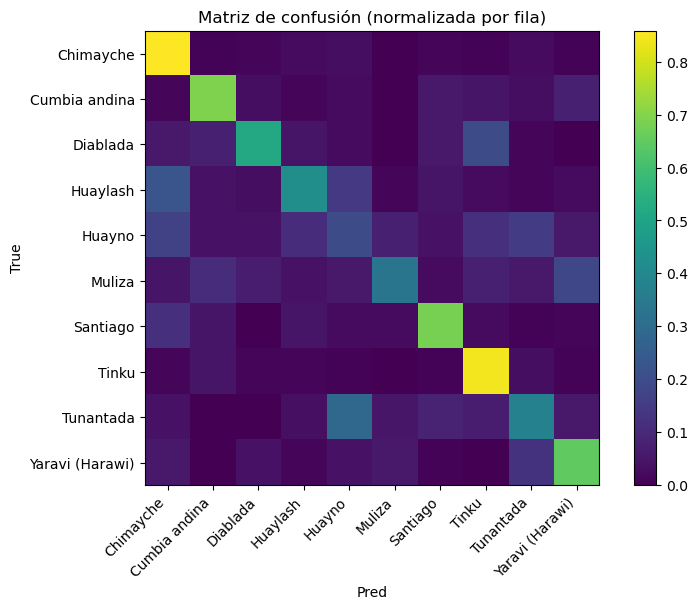

Matriz de confusión (absoluta):
[[103   1   2   3   4   0   2   1   3   1]
 [  2  83   4   2   3   0   7   6   4   9]
 [  7   9  62   6   3   0   7  24   2   0]
 [ 27   5   4  51  17   2   6   3   2   3]
 [ 20   5   5  13  24   9   5  14  18   7]
 [  6  13   8   5   7  40   3   9   7  22]
 [ 14   6   0   6   3   3  82   3   1   2]
 [  2   6   2   2   1   0   1 101   4   1]
 [  5   0   0   4  34   6  10   8  45   7]
 [  7   0   5   2   5   7   1   0  15  78]]

Reporte de clasificación (macro/weighted):

                 precision    recall  f1-score   support

      Chimayche     0.5337    0.8583    0.6581       120
  Cumbia andina     0.6484    0.6917    0.6694       120
       Diablada     0.6739    0.5167    0.5849       120
       Huaylash     0.5426    0.4250    0.4766       120
         Huayno     0.2376    0.2000    0.2172       120
         Muliza     0.5970    0.3333    0.4278       120
       Santiago     0.6613    0.6833    0.6721       120
          Tinku     0.5976    0.841

In [6]:
# ==== PREDICCIONES EN TEST ====
import torch
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true, y_pred = [], []
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

with torch.no_grad():
    for x, y in dm.test_dataloader():
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        logits = model(x)
        preds = torch.argmax(logits, dim=1)
        y_true.append(y.cpu().numpy())
        y_pred.append(preds.cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)

# ==== MATRIZ DE CONFUSIÓN (normalizada y absoluta) ====
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8,6))
plt.imshow(cm_norm, interpolation='nearest')
plt.title("Matriz de confusión (normalizada por fila)")
plt.colorbar()
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45, ha='right')
plt.yticks(tick_marks, classes)
plt.tight_layout()
plt.ylabel('True')
plt.xlabel('Pred')
plt.show()

print("Matriz de confusión (absoluta):")
print(cm)

# ==== REPORTE DE CLASIFICACIÓN ====
print("\nReporte de clasificación (macro/weighted):\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=4))


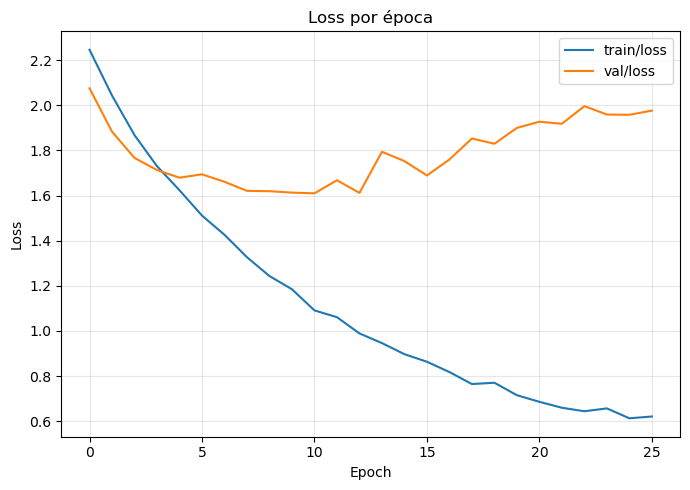

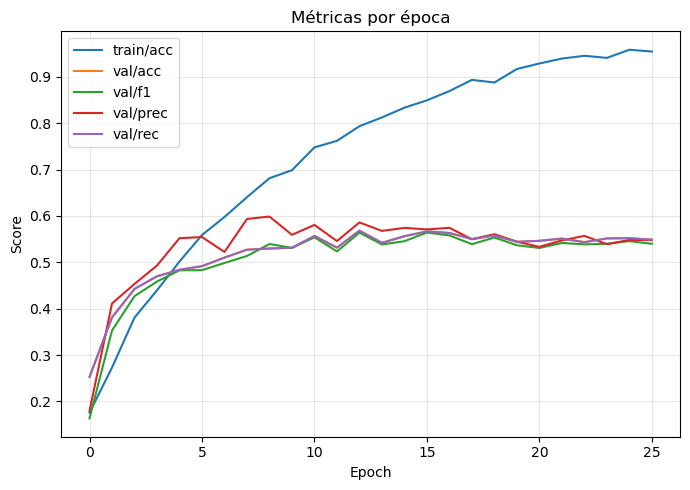

In [7]:
# ==== CURVAS DESDE metrics.csv ====
import pandas as pd
import matplotlib.pyplot as plt

assert metrics_csv is not None and metrics_csv.exists(), "No se encontró metrics.csv"
df = pd.read_csv(metrics_csv).dropna(subset=["epoch"])

# Para limpiar múltiples filas por época, nos quedamos con la última por época:
agg = df.groupby("epoch").agg("last").reset_index()

# Curva de Loss
plt.figure(figsize=(7,5))
for col in ["train/loss", "val/loss"]:
    if col in agg.columns:
        plt.plot(agg["epoch"], agg[col], label=col)
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Loss por época")
plt.grid(True, alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

# Curvas de métricas principales
plt.figure(figsize=(7,5))
for col in ["train/acc","val/acc","val/f1","val/prec","val/rec"]:
    if col in agg.columns:
        plt.plot(agg["epoch"], agg[col], label=col)
plt.xlabel("Epoch"); plt.ylabel("Score")
plt.title("Métricas por época")
plt.grid(True, alpha=.3); plt.legend(); plt.tight_layout(); plt.show()


In [19]:
from pathlib import Path
import pandas as pd

log_dir = Path("logs/vit")   # o "logs/vit_tl"
versions = sorted(log_dir.glob("version_*"), key=lambda p: int(p.name.split("_")[-1]))
csv_path = versions[-1]/"metrics.csv"
df = pd.read_csv(csv_path).dropna(subset=["epoch"])
agg = df.groupby("epoch").agg("last").reset_index()

cols = ["train/loss","val/loss","train/acc","val/acc","val/f1","val/prec","val/rec"]
present = [c for c in cols if c in agg.columns]
display(agg[["epoch"]+present].tail(10))

# Regla rápida para “¿hay overfitting?”:
def verdict(row, acc_gap_thr=0.10, loss_gap_thr=0.30):
    gap_acc  = row.get("train/acc", float("nan")) - row.get("val/acc", float("nan"))
    gap_loss = row.get("val/loss", float("nan")) - row.get("train/loss", float("nan"))
    flags = []
    if pd.notna(gap_acc) and gap_acc > acc_gap_thr:  # >10 pts
        flags.append("brecha_acc")
    if pd.notna(gap_loss) and gap_loss > loss_gap_thr:  # val_loss > train_loss por margen
        flags.append("brecha_loss")
    return gap_acc, gap_loss, flags

last = agg.iloc[-1].to_dict()
gap_acc, gap_loss, flags = verdict(last)
print(f"gap_acc={gap_acc:.3f} | gap_loss={gap_loss:.3f} | flags={flags}")


,epoch,train/loss,val/loss,train/acc,val/acc,val/f1,val/prec,val/rec
11,11.0,1.133553,1.520796,0.729270,0.588404,0.585859,0.606929,0.588404
12,12.0,1.084549,1.611263,0.751796,0.579610,0.566554,0.591198,0.579610
13,13.0,1.040205,1.526437,0.768021,0.597739,0.590082,0.600382,0.597739
14,14.0,0.990703,1.559001,0.789828,0.584574,0.580809,0.605872,0.584574
15,15.0,0.933990,1.558239,0.815089,0.597190,0.603244,0.623268,0.597190
16,16.0,0.894949,1.573095,0.835465,0.599840,0.601873,0.619525,0.599840
17,17.0,0.904703,1.636435,0.829043,0.590133,0.593661,0.620538,0.590133
18,18.0,0.849849,1.679430,0.853110,0.583342,0.590803,0.616762,0.583342
19,19.0,0.809291,1.749553,0.872289,0.579450,0.577592,0.613029,0.579450
20,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


gap_acc=nan | gap_loss=nan | flags=[]
